Kelompok "Kata Ifsal senormal mungkin aja"

Tema: Strategi Penurunan Risiko Kredit Macet Berdasarkan Segmentasi Perilaku Finansial Pelanggan

Anggota: 
1. Ananda Rizky Setya N.	(123240070)
2. Fahmi Firdaus            (123240055)
3. Nailah Hana Nur’aisyah	(123240088)
4. Muhamad Ifsal Fadhilah	(123240138)

Link dataset: https://www.kaggle.com/datasets/faisalwp/dataset-klasifikasi-status-pinjaman

# Bussiness Understanding

Metode Clasification

In [142]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
# from sklearn.preprocessing import OrdinalEncoder, LabelEncoder,OneHotEncoder
# from sklearn.ensemble import RandomForestClassifier
# from sklearn.model_selection import train_test_split
# from sklearn.metrics import classification_report
# from sklearn.metrics import confusion_matrix

In [143]:
df = pd.read_csv('data/data.csv')
df.head()
# df.info()

,id_pelanggan,usia,status_pekerjaan,lama_bekerja_tahun,pendapatan_tahunan,skor_kredit,lama_riwayat_kredit_tahun,aset_tabungan,hutang_saat_ini,gagal_bayar_tercatat,tunggakan_2thn_terakhir,catatan_negatif,tipe_produk,tujuan_pinjaman,jumlah_pinjaman,suku_bunga,rasio_hutang_terhadap_pendapatan,rasio_pinjaman_terhadap_pendapatan,rasio_pembayaran_terhadap_pendapatan,status_pinjaman
0,CUST100000,40.0,Bekerja,17.2,25579,692,5.3,895,10820,0,0,0,Kartu Kredit,Bisnis,600,17.02,0.423,0.023,0.008,1
1,CUST100001,33.0,Bekerja,7.3,43087,627,3.5,169,16550,0,1,0,Pinjaman Pribadi,Renovasi Rumah,53300,14.10,0.384,1.237,0.412,0
2,CUST100002,42.0,Mahasiswa,1.1,20840,689,8.4,17,7852,0,0,0,Kartu Kredit,Konsolidasi Hutang,2100,18.33,0.377,0.101,0.034,1
3,CUST100003,53.0,Mahasiswa,0.5,29147,692,9.8,1480,11603,0,1,0,Kartu Kredit,Bisnis,2900,18.74,0.398,0.099,0.033,1
4,CUST100004,32.0,Bekerja,12.5,63657,630,7.2,209,12424,0,0,0,Pinjaman Pribadi,Pendidikan,99600,13.92,0.195,1.565,0.522,1


### Missing Value

Terdapat missing value pada kolom/variabel usia dan status_pekerjaan yang masing-masing berjumlah 147 dan 153, karena presentasenya sangat kecil (< 0.4%).

solusi:
- usia: melakukan imputasi data dengan menggunakan median
- status_pekerjaan: melakukan imputasi data dengan menggunakan modus

In [144]:
df.isnull().sum()
# print(df.isnull().mean()*100)


id_pelanggan                              0
usia                                    147
status_pekerjaan                        153
lama_bekerja_tahun                        0
pendapatan_tahunan                        0
skor_kredit                               0
lama_riwayat_kredit_tahun                 0
aset_tabungan                             0
hutang_saat_ini                           0
gagal_bayar_tercatat                      0
tunggakan_2thn_terakhir                   0
catatan_negatif                           0
tipe_produk                               0
tujuan_pinjaman                           0
jumlah_pinjaman                           0
suku_bunga                                0
rasio_hutang_terhadap_pendapatan          0
rasio_pinjaman_terhadap_pendapatan        0
rasio_pembayaran_terhadap_pendapatan      0
status_pinjaman                           0
dtype: int64

In [145]:
df['usia'] = df['usia'].fillna(df.groupby('status_pekerjaan')['usia'].transform('median'))
print("Sisa missing value pada kolom usia:", df['usia'].isnull().sum())

modus_pekerjaan = df['status_pekerjaan'].mode()[0]
df['status_pekerjaan'] = df['status_pekerjaan'].fillna(modus_pekerjaan)
print("Sisa missing value pada kolom status_pekerjaan:", df['status_pekerjaan'].isnull().sum())

df.isnull().sum()

Sisa missing value pada kolom usia: 0
Sisa missing value pada kolom status_pekerjaan: 0


id_pelanggan                            0
usia                                    0
status_pekerjaan                        0
lama_bekerja_tahun                      0
pendapatan_tahunan                      0
skor_kredit                             0
lama_riwayat_kredit_tahun               0
aset_tabungan                           0
hutang_saat_ini                         0
gagal_bayar_tercatat                    0
tunggakan_2thn_terakhir                 0
catatan_negatif                         0
tipe_produk                             0
tujuan_pinjaman                         0
jumlah_pinjaman                         0
suku_bunga                              0
rasio_hutang_terhadap_pendapatan        0
rasio_pinjaman_terhadap_pendapatan      0
rasio_pembayaran_terhadap_pendapatan    0
status_pinjaman                         0
dtype: int64

### Duplikasi

Pada data ini tidak terdapat duplikasi data jadi skip

In [146]:
df.duplicated().sum()

np.int64(0)

### Outlier

In [147]:
numeric_cols = ['pendapatan_tahunan', 'aset_tabungan', 'hutang_saat_ini', 'jumlah_pinjaman', 'skor_kredit']
outliers_summary = {}

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    count = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    outliers_summary[col] = count

for k, v in outliers_summary.items():
    print(f"- Kolom {k}: ditemukan {v} data pencilan (outlier)")

- Kolom pendapatan_tahunan: ditemukan 2355 data pencilan (outlier)
- Kolom aset_tabungan: ditemukan 6508 data pencilan (outlier)
- Kolom hutang_saat_ini: ditemukan 2932 data pencilan (outlier)
- Kolom jumlah_pinjaman: ditemukan 0 data pencilan (outlier)
- Kolom skor_kredit: ditemukan 349 data pencilan (outlier)


In [148]:
z_outliers_summary = {}

for col in numeric_cols:
    # Menghitung Z-score untuk setiap nilai
    z_scores = np.abs((df[col] - df[col].mean()) / df[col].std())
    # Menghitung jumlah data yang nilai absolut Z-score nya > 3
    count = (z_scores > 3).sum()
    z_outliers_summary[col] = count

for col, count in z_outliers_summary.items():
    print(f"- Kolom {col}: ditemukan {count} outlier berdasarkan ambang batas Z-score > 3")

- Kolom pendapatan_tahunan: ditemukan 940 outlier berdasarkan ambang batas Z-score > 3
- Kolom aset_tabungan: ditemukan 642 outlier berdasarkan ambang batas Z-score > 3
- Kolom hutang_saat_ini: ditemukan 1015 outlier berdasarkan ambang batas Z-score > 3
- Kolom jumlah_pinjaman: ditemukan 0 outlier berdasarkan ambang batas Z-score > 3
- Kolom skor_kredit: ditemukan 132 outlier berdasarkan ambang batas Z-score > 3


## EDA


--- KORELASI FITUR TERHADAP STATUS PINJAMAN ---
status_pinjaman                         1.000000
skor_kredit                             0.496316
usia                                    0.311076
lama_riwayat_kredit_tahun               0.277103
lama_bekerja_tahun                      0.218875
pendapatan_tahunan                      0.158466
aset_tabungan                           0.094789
jumlah_pinjaman                        -0.025987
hutang_saat_ini                        -0.088494
suku_bunga                             -0.185179
rasio_pinjaman_terhadap_pendapatan     -0.193252
rasio_pembayaran_terhadap_pendapatan   -0.193258
catatan_negatif                        -0.224735
gagal_bayar_tercatat                   -0.263033
rasio_hutang_terhadap_pendapatan       -0.317363
tunggakan_2thn_terakhir                -0.318075
Name: status_pinjaman, dtype: float64


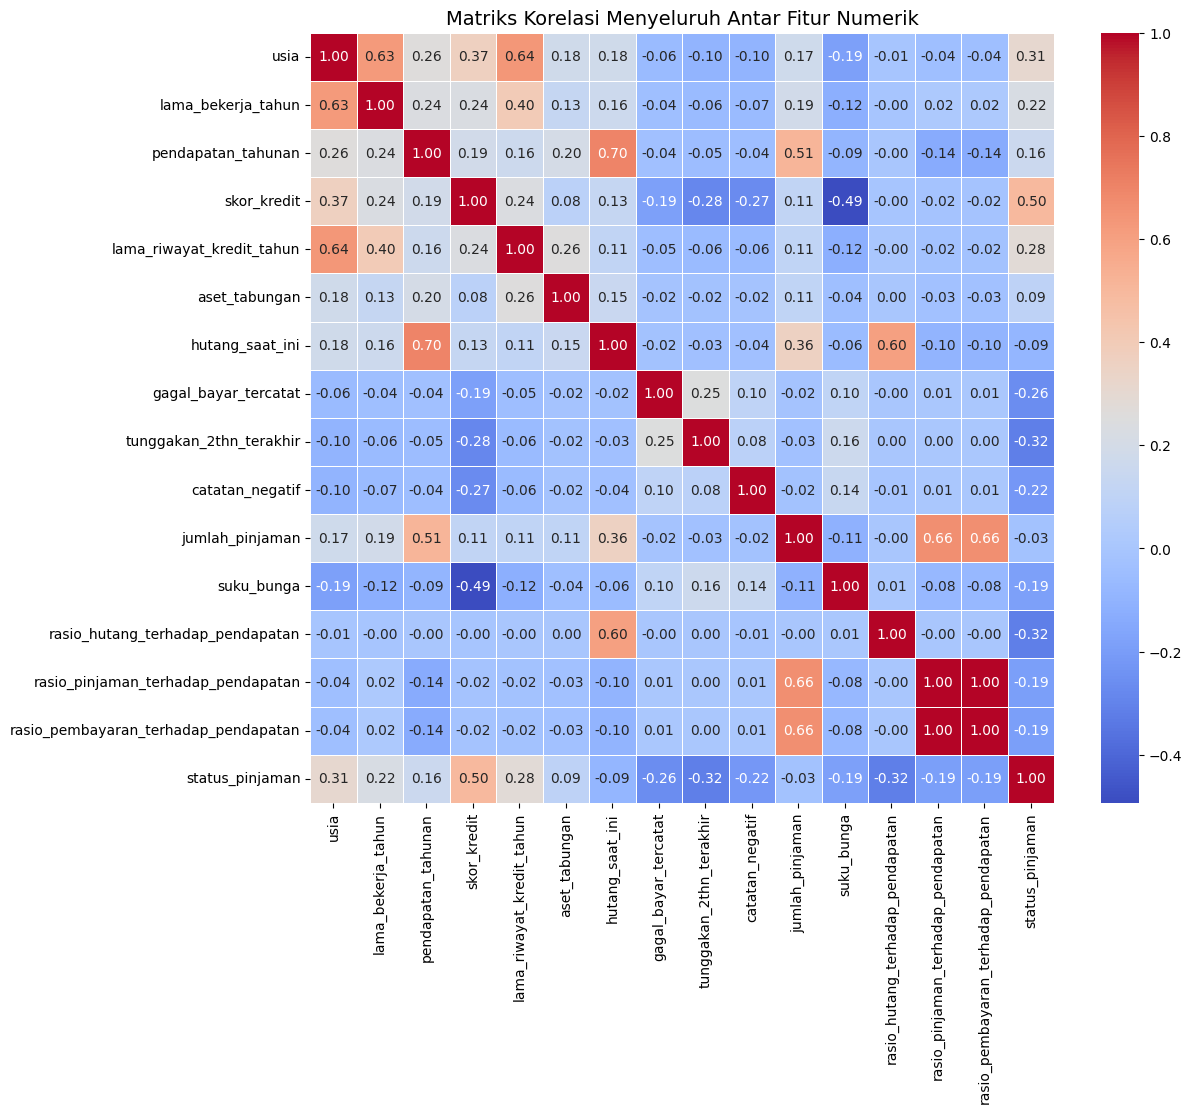

In [155]:
# 2. Mengambil seluruh kolom numerik
numeric_df = df.select_dtypes(include=[np.number])

# 3. Menghitung Matriks Korelasi Keseluruhan (Pearson Correlation)
correlation_matrix = numeric_df.corr()

# print("--- MATRIKS KORELASI KESELURUHAN (SAMPLE) ---")
# print(correlation_matrix.iloc[:5, :5]) # Menampilkan sampel 5x5 kolom pertama

# 4. Korelasi Spesifik terhadap Target (status_pinjaman)
print("\n--- KORELASI FITUR TERHADAP STATUS PINJAMAN ---")
target_corr = correlation_matrix['status_pinjaman'].sort_values(ascending=False)
print(target_corr)

# 5. Visualisasi Heatmap Korelasi Seluruh Fitur Numerik
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, cbar=True)
plt.title('Matriks Korelasi Menyeluruh Antar Fitur Numerik', fontsize=14)
plt.savefig('heatmap_korelasi_seluruh_fitur.png', dpi=300, bbox_inches='tight')
plt.show()

--- 1. DISTRIBUSI VARIABEL TARGET (status_pinjaman) ---
Lancar (1): 27523 nasabah (55.05%)
Macet/Default (0): 22477 nasabah (44.95%)



C:\Users\Asus\AppData\Local\Temp\ipykernel_14112\1814960068.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='status_pinjaman', data=df, palette='Set2')


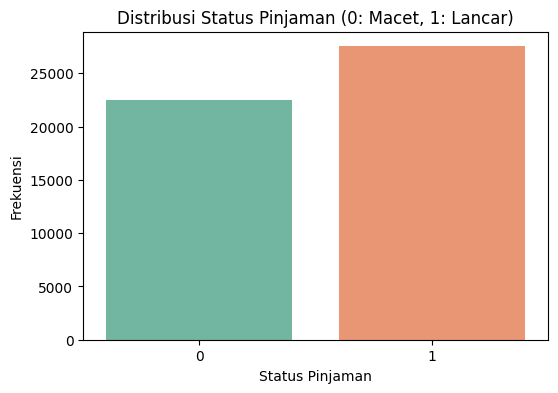

In [150]:
print("--- 1. DISTRIBUSI VARIABEL TARGET (status_pinjaman) ---")
target_counts = df['status_pinjaman'].value_counts()
target_pct = df['status_pinjaman'].value_counts(normalize=True) * 100
print(f"Lancar (1): {target_counts[1]} nasabah ({target_pct[1]:.2f}%)")
print(f"Macet/Default (0): {target_counts[0]} nasabah ({target_pct[0]:.2f}%)\n")

# Visualisasi Bar Plot Target
plt.figure(figsize=(6, 4))
sns.countplot(x='status_pinjaman', data=df, palette='Set2')
plt.title('Distribusi Status Pinjaman (0: Macet, 1: Lancar)')
plt.xlabel('Status Pinjaman')
plt.ylabel('Frekuensi')
plt.savefig('distribusi_target.png', dpi=300, bbox_inches='tight')
plt.show()

In [151]:
print("--- 2. ANALISIS SKEWNESS FITUR NUMERIK ---")
# numeric_cols = ['pendapatan_tahunan', 'aset_tabungan', 'hutang_saat_ini', 'jumlah_pinjaman', 'skor_kredit']
skewness_vals = df[numeric_cols].skew()
print(skewness_vals)
print("\n")

--- 2. ANALISIS SKEWNESS FITUR NUMERIK ---
pendapatan_tahunan     1.887869
aset_tabungan         12.054946
hutang_saat_ini        2.437837
jumlah_pinjaman        0.931492
skor_kredit            0.012996
dtype: float64




In [152]:
# print("\n--- 3. ANALISIS BIVARIAT: STATUS PEKERJAAN VS STATUS PINJAMAN ---")
cross_tab = pd.crosstab(df['status_pekerjaan'], df['status_pinjaman'], normalize='index') * 100
print(cross_tab)


status_pinjaman           0          1
status_pekerjaan                      
Bekerja           45.640747  54.359253
Mahasiswa         43.863636  56.136364
Wiraswasta        43.106165  56.893835



--- ANALISIS KORELASI FITUR TERHADAP TARGET ---
status_pinjaman                         1.000000
skor_kredit                             0.496316
usia                                    0.311076
lama_riwayat_kredit_tahun               0.277103
lama_bekerja_tahun                      0.218875
pendapatan_tahunan                      0.158466
aset_tabungan                           0.094789
jumlah_pinjaman                        -0.025987
hutang_saat_ini                        -0.088494
suku_bunga                             -0.185179
rasio_pinjaman_terhadap_pendapatan     -0.193252
rasio_pembayaran_terhadap_pendapatan   -0.193258
catatan_negatif                        -0.224735
gagal_bayar_tercatat                   -0.263033
rasio_hutang_terhadap_pendapatan       -0.317363
tunggakan_2thn_terakhir                -0.318075
Name: status_pinjaman, dtype: float64


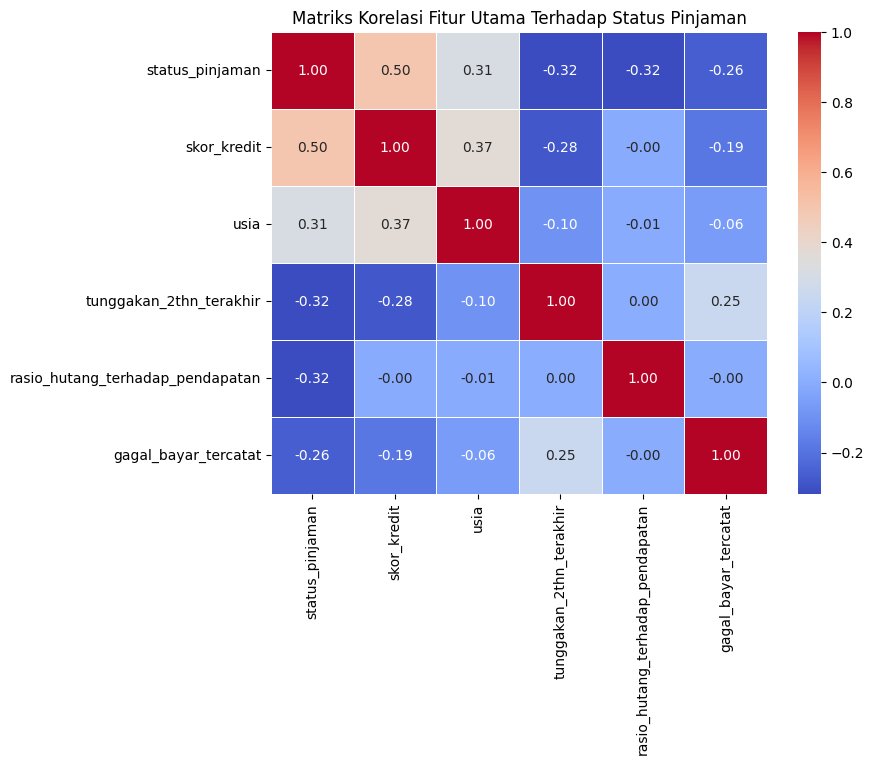

In [153]:
# B. Analisis Korelasi Fitur Numerik Terhadap Target
print("\n--- ANALISIS KORELASI FITUR TERHADAP TARGET ---")
corr_matrix = df.select_dtypes(include=[np.number]).corr()
target_corr = corr_matrix['status_pinjaman'].sort_values(ascending=False)
print(target_corr)

# Visualisasi Heatmap Korelasi Fitur Utama
key_features = ['status_pinjaman', 'skor_kredit', 'usia', 'tunggakan_2thn_terakhir', 'rasio_hutang_terhadap_pendapatan', 'gagal_bayar_tercatat']
plt.figure(figsize=(8, 6))
sns.heatmap(df[key_features].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Matriks Korelasi Fitur Utama Terhadap Status Pinjaman')
plt.savefig('heatmap_korelasi.png', dpi=300, bbox_inches='tight')
plt.show()